In [ ]:
!pip install scikit-learn openpyxl -q

In [ ]:
import pandas as pd  #These libraries help us handle data, create graphs, group products, and predict demand.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

print("StockSense Started!")

StockSense Started!


In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(next(iter(uploaded)))

print("Dataset loaded")
print(df.shape)
display(df.head())

Saving Online Retail.xlsx to Online Retail (1).xlsx
Dataset loaded
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Data Cleaning

In [ ]:
#data cleaning
df = df.drop_duplicates()
df = df.dropna(subset=[
    "StockCode", "Quantity", "InvoiceDate"
])
df = df[df["Quantity"] > 0]
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Cleaned data:")
display(df.head())

Cleaned data:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Find the most demanded products

In [ ]:
products = df.groupby("StockCode")["Quantity"].sum()
products = products.sort_values(ascending=False)
print("Top 10 products:")
display(products.head(10))

Top 10 products:


,Quantity
StockCode,
23843,80995
23166,78033
22197,56898
84077,54951
85099B,48375
85123A,41645
21212,36396
84879,36362
23084,31673


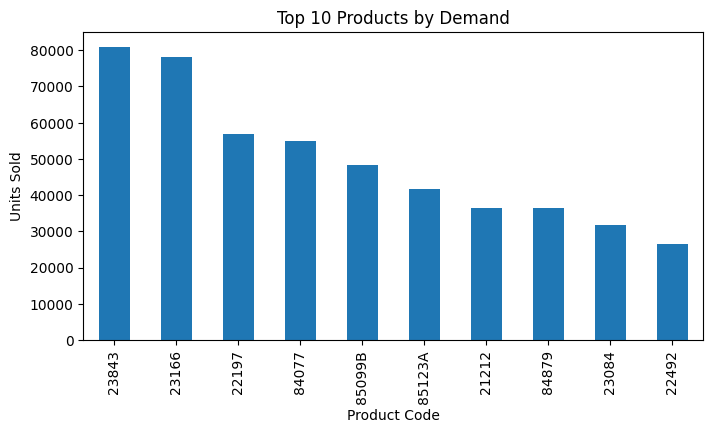

In [ ]:
#We calculate total units sold for each product and identify the products with the highest historical demand.
products.head(10).plot(kind="bar", figsize=(8, 4))

plt.title("Top 10 Products by Demand")
plt.xlabel("Product Code")
plt.ylabel("Units Sold")
plt.show()

# Apply K-Means clustering

In [ ]:
#K-Means groups similar products. The three groups may represent different sales patterns; we
#examine their averages to understand which groups have higher demand.
product_data = df.groupby("StockCode").agg(
    Total_Sales=("Quantity", "sum"),
    Total_Revenue=("UnitPrice", "sum")
).reset_index()

X = np.log1p(
    product_data[["Total_Sales", "Total_Revenue"]].clip(lower=0)
)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

product_data["Cluster"] = kmeans.fit_predict(X)

display(product_data.head(10))

,StockCode,Total_Sales,Total_Revenue,Cluster
0,10002,1040,77.15,1
1,10080,495,9.04,1
2,10120,192,6.09,1
3,10125,1295,79.96,1
4,10133,2856,127.90,2
5,10135,2229,250.08,2
6,11001,1615,217.35,2
7,15030,293,3.77,1
8,15034,6591,51.61,2
9,15036,23826,554.17,2


In [ ]:
print(
    product_data.groupby("Cluster")["Total_Sales"].mean()
)

Cluster
0      20.636062
1     401.983311
2    3264.582846
Name: Total_Sales, dtype: float64


# Prepare daily demand data

In [ ]:
#We convert transaction records into daily product demand and create features from previous sales.
top_products = products.head(10).index.tolist()

df["Date"] = df["InvoiceDate"].dt.normalize()

daily = df[df["StockCode"].isin(top_products)]

daily = daily.groupby(
    ["Date", "StockCode"]
)["Quantity"].sum().reset_index(name="Demand")

dates = pd.date_range(daily["Date"].min(), daily["Date"].max())

index = pd.MultiIndex.from_product(
    [dates, top_products], names=["Date", "StockCode"]
)

daily = (
    daily.set_index(["Date", "StockCode"])
    .reindex(index, fill_value=0)
    .reset_index()
)

daily = daily.sort_values(["StockCode", "Date"])

daily["Previous_Day"] = daily.groupby("StockCode")["Demand"].shift(1)

daily["Average_7_Days"] = daily.groupby("StockCode")["Demand"].transform(
    lambda x: x.shift(1).rolling(7).mean()
)

daily["Day"] = daily["Date"].dt.dayofweek

daily = daily.dropna()

display(daily.head())

,Date,StockCode,Demand,Previous_Day,Average_7_Days,Day
76,2010-12-08,21212,134,261.0,196.714286,2
86,2010-12-09,21212,77,134.0,181.428571,3
96,2010-12-10,21212,486,77.0,126.857143,4
106,2010-12-11,21212,0,486.0,160.000000,5
116,2010-12-12,21212,5,0.0,160.000000,6


# Train the Random Forest model

In [ ]:
features = ["Previous_Day", "Average_7_Days", "Day"]

cutoff = daily["Date"].max() - pd.Timedelta(days=30)

train = daily[daily["Date"] <= cutoff]
test = daily[daily["Date"] > cutoff]

X_train = train[features]
y_train = train["Demand"]

X_test = test[features]
y_test = test["Demand"]

model = RandomForestRegressor(
    n_estimators=50,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained successfully!")
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))

Model trained successfully!
Mean Absolute Error: 407.43024657549466


# Predict next-day demand

In [ ]:
next_date = daily["Date"].max() + pd.Timedelta(days=1)

future = daily.groupby("StockCode").tail(1).copy()

future["Previous_Day"] = future["Demand"]

future["Average_7_Days"] = future["StockCode"].map(
    daily.groupby("StockCode")["Demand"].apply(
        lambda x: x.tail(7).mean()
    )
)

future["Day"] = next_date.dayofweek

future["Predicted_Demand"] = np.maximum(
    model.predict(future[features]), 0
)

display(future[[
    "StockCode", "Predicted_Demand"
]])

,StockCode,Predicted_Demand
3736,21212,0.0
3732,22197,0.0
3739,22492,0.0
3738,23084,0.0
3731,23166,0.0
3730,23843,0.0
3733,84077,0.0
3737,84879,0.0
3734,85099B,0.0
3735,85123A,0.0


# Detect inventory shortages

In [ ]:
#: We compare available stock with the reorder point. If available stock is less than or equal to the reorder point, the system displays a low-stock alert.
np.random.seed(42)

stock = future[["StockCode", "Predicted_Demand"]].copy()

stock["Available_Stock"] = np.random.randint(
    5, 101, size=len(stock)
)

stock["Lead_Time"] = 3

stock["Safety_Stock"] = np.ceil(
    stock["Predicted_Demand"] * 2
)

stock["Reorder_Point"] = np.ceil(
    stock["Predicted_Demand"] * stock["Lead_Time"]
    + stock["Safety_Stock"]
)

stock["Status"] = np.where(
    stock["Available_Stock"] <= stock["Reorder_Point"],
    "Low Stock",
    "Stock Available"
)

stock["Reorder_Quantity"] = np.maximum(
    stock["Reorder_Point"] - stock["Available_Stock"], 0
)

display(stock)

,StockCode,Predicted_Demand,Available_Stock,Lead_Time,Safety_Stock,Reorder_Point,Status,Reorder_Quantity
3736,21212,0.0,56,3,0.0,0.0,Stock Available,0.0
3732,22197,0.0,97,3,0.0,0.0,Stock Available,0.0
3739,22492,0.0,19,3,0.0,0.0,Stock Available,0.0
3738,23084,0.0,76,3,0.0,0.0,Stock Available,0.0
3731,23166,0.0,65,3,0.0,0.0,Stock Available,0.0
3730,23843,0.0,25,3,0.0,0.0,Stock Available,0.0
3733,84077,0.0,87,3,0.0,0.0,Stock Available,0.0
3737,84879,0.0,91,3,0.0,0.0,Stock Available,0.0
3734,85099B,0.0,79,3,0.0,0.0,Stock Available,0.0
3735,85123A,0.0,79,3,0.0,0.0,Stock Available,0.0


# Show the final shortage report

In [ ]:
alerts = stock[stock["Status"] == "Low Stock"]

print("Total Products:", len(stock))
print("Products Requiring Reorder:", len(alerts))

display(alerts)

alerts.to_csv("StockSense_Report.csv", index=False)

Total Products: 10
Products Requiring Reorder: 0


,StockCode,Predicted_Demand,Available_Stock,Lead_Time,Safety_Stock,Reorder_Point,Status,Reorder_Quantity


In [ ]:
files.download("StockSense_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q streamlit pandas numpy

In [50]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np

st.set_page_config(
    page_title="StockSense",
    page_icon="📦",
    layout="wide"
)

st.title("📦 StockSense")
st.subheader("Inventory Shortage Prediction and Product Demand Mining")

st.write(
    "StockSense analyzes product demand and helps identify "
    "products that may require restocking."
)

st.info(
    "Educational project: sample inventory values are simulated. "
    "Upload your own report to see your results."
)

# Upload the inventory report
uploaded_file = st.file_uploader(
    "Upload StockSense_Report.csv",
    type=["csv"]
)

# Use uploaded data, or create sample data for the first demonstration
if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)
else:
    data = pd.DataFrame({
        "StockCode": ["P101", "P102", "P103", "P104", "P105"],
        "Predicted_Demand": [20, 15, 35, 10, 25],
        "Available_Stock": [12, 60, 15, 40, 18],
        "Reorder_Point": [30, 25, 45, 20, 35]
    })

    data["Status"] = np.where(
        data["Available_Stock"] <= data["Reorder_Point"],
        "Low Stock",
        "Stock Available"
    )

    st.caption(
        "Showing demonstration data. Upload your CSV for actual report values."
    )

# Support the column names from either version of the notebook
if "Predicted_Daily_Demand" in data.columns:
    demand_col = "Predicted_Daily_Demand"
elif "Predicted_Demand" in data.columns:
    demand_col = "Predicted_Demand"
else:
    demand_col = None

if "Status" in data.columns:
    status_col = "Status"
elif "Shortage_Status" in data.columns:
    status_col = "Shortage_Status"
else:
    status_col = None

# Dashboard summary
total_products = len(data)

if status_col:
    low_stock = data[status_col].astype(str).isin(
        ["Low Stock", "REORDER REQUIRED"]
    ).sum()
else:
    low_stock = 0

if demand_col:
    total_demand = round(data[demand_col].fillna(0).sum(), 2)
else:
    total_demand = 0

c1, c2, c3 = st.columns(3)

c1.metric("Total Products", total_products)
c2.metric("Low Stock Alerts", int(low_stock))
c3.metric("Predicted Demand", total_demand)

# Demand chart
st.header("📊 Product Demand Analysis")

if demand_col and "StockCode" in data.columns:
    chart_data = data.set_index("StockCode")[[demand_col]]
    st.bar_chart(chart_data)
else:
    st.warning("The uploaded report does not contain a demand prediction column.")

# Inventory table
st.header("📦 Inventory Report")
st.dataframe(data, use_container_width=True)

# Low stock alerts
st.header("⚠️ Products Requiring Restocking")

if status_col:
    alerts = data[
        data[status_col].astype(str).isin(
            ["Low Stock", "REORDER REQUIRED"]
        )
    ]

    if len(alerts) > 0:
        st.dataframe(alerts, use_container_width=True)
    else:
        st.success("No low-stock alerts found in this report.")
else:
    st.warning("The uploaded report does not contain a stock status column.")

# Download the displayed report
csv_data = data.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Inventory Report",
    data=csv_data,
    file_name="StockSense_Report.csv",
    mime="text/csv"
)

st.caption("StockSense | Data Mining Project")


Overwriting app.py


In [51]:

%%writefile requirements.txt
streamlit
pandas
numpy


Writing requirements.txt


In [52]:

from google.colab import files

files.download("app.py")
files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>